# 08.2 · One neuron, by hand and in NumPy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/02-one-neuron/lesson.ipynb)

Read the [README](README.md) and do the by-hand calculation first. This notebook repeats it in NumPy and Keras, then shows that one neuron *is* the logistic regression you trained in Module 03.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. One neuron, step by step

In [2]:
x = np.array([1.5, -0.5, -0.8])      # C042: days_since_last, orders, spend (scaled)
w = np.array([0.9, -1.1, -0.4])      # weights
b = -0.3                             # bias

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

contributions = w * x
print("w × x for each input:", contributions.round(2), " sum:", contributions.sum().round(2))
z = x @ w + b
print("z =", round(z, 2))
print("sigmoid(z) =", round(sigmoid(z), 3))

w × x for each input: [1.35 0.55 0.32]  sum: 2.22
z = 1.92
sigmoid(z) = 0.872


Same as the README: $z = 1.92$, churn probability $0.872$.

The `@` operator is a **dot product**: multiply matching entries and add them up. It is the whole weighted sum in one symbol.

## 2. What the weights mean

Move one input at a time and watch the output. Long silence raises the churn probability; more orders lower it.

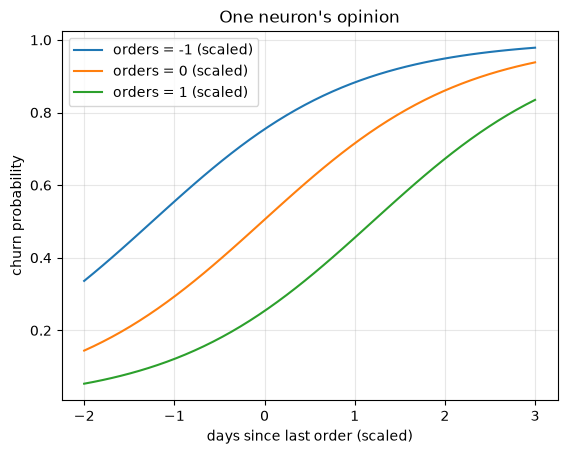

In [3]:
days = np.linspace(-2, 3, 50)
for orders in [-1, 0, 1]:
    p = sigmoid(w[0] * days + w[1] * orders + w[2] * (-0.8) + b)
    plt.plot(days, p, label=f"orders = {orders} (scaled)")
plt.xlabel("days since last order (scaled)"); plt.ylabel("churn probability")
plt.title("One neuron's opinion"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 3. A layer is a matrix multiplication

Three customers, four neurons. Write the shapes before you multiply: (3 × 3) · (3 × 4) → (3 × 4).

In [4]:
X = np.array([[ 1.5, -0.5, -0.8],    # C042
              [-0.7,  1.2,  0.9],    # a loyal customer
              [ 0.2,  0.0, -0.1]])   # an average customer
W = np.array([[ 0.9, -0.2,  0.5,  0.1],
              [-1.1,  0.4,  0.3, -0.6],
              [-0.4,  0.7, -0.2,  0.8]])
bias = np.array([-0.3, 0.1, 0.0, 0.2])

H = X @ W + bias
print("shapes:", X.shape, "@", W.shape, "+", bias.shape, "→", H.shape)
print(H.round(2))
print("parameters in this layer:", W.size + bias.size)

shapes: (3, 3) @ (3, 4) + (4,) → (3, 4)
[[ 1.92 -0.96  0.76  0.01]
 [-2.61  1.35 -0.17  0.13]
 [-0.08 -0.01  0.12  0.14]]
parameters in this layer: 16


Row 1, column 1 is C042's neuron from section 1: 1.92. Row 2, column 2 is the 1.35 checked by hand in the README.

Hidden layers usually apply **ReLU**, $\max(0, z)$, which keeps positives and zeroes negatives:

In [5]:
print(np.maximum(H, 0).round(2))

[[1.92 0.   0.76 0.01]
 [0.   1.35 0.   0.13]
 [0.   0.   0.12 0.14]]


## 4. The same layer in Keras

`keras.layers.Dense(4)` is exactly this computation. We give it our hand-picked weights instead of random ones and check it agrees.

In [6]:
import keras
from keras import layers
keras.utils.set_random_seed(42)      # same starting weights every run (small differences across machines are normal)
print("Keras", keras.__version__, "on", keras.backend.backend())

layer = layers.Dense(4)                # no activation: just X @ W + b
layer.build((None, 3))                 # None = any number of customers, 3 features each
layer.set_weights([W, bias])
print(np.asarray(layer(X)).round(2))

Keras 3.15.1 on tensorflow
[[ 1.92 -0.96  0.76  0.01]
 [-2.61  1.35 -0.17  0.13]
 [-0.08 -0.01  0.12  0.14]]


Identical. `None` in a shape means "any batch size": a layer does not care how many customers you pass at once.

## 5. One sigmoid neuron *is* logistic regression

Train scikit-learn's logistic regression on the real ShopWave churn table, then copy its learned weights into a single Keras neuron.

In [7]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)            # fit on training customers only (lesson 04.5)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
logreg = LogisticRegression(max_iter=1000).fit(Xs_train, y_train)
print(f"Logistic regression test AUC: {roc_auc_score(y_test, logreg.predict_proba(Xs_test)[:, 1]):.3f}")

print("coefficients:", logreg.coef_[0].round(3), " intercept:", logreg.intercept_.round(3))

Logistic regression test AUC: 0.741
coefficients: [-0.992  0.06  -0.45  -0.173  0.437]  intercept: [-0.476]


In [9]:
neuron = keras.Sequential([keras.Input((5,)), layers.Dense(1, activation="sigmoid")])
neuron.layers[0].set_weights([logreg.coef_.T, logreg.intercept_])   # shapes (5, 1) and (1,)

p_keras = neuron.predict(Xs_test, verbose=0).ravel()
p_sklearn = logreg.predict_proba(Xs_test)[:, 1]
print(f"largest difference over {len(p_keras)} test customers: {np.abs(p_keras - p_sklearn).max():.1e}")

largest difference over 830 test customers: 1.4e-07


Differences of about one ten-millionth: floating-point rounding, nothing more. A one-neuron network with a sigmoid **is** logistic regression. The difference is only in *how the weights get learned*: scikit-learn solves for them directly, a network learns them by gradient descent (lessons 08.4 and 08.5).

Notice the coefficient order follows the feature columns `orders, spend, products, tenure_days, days_since_last`: more orders push churn down (−0.99), long silence pushes it up (+0.44).

## Quiz answers

1. A weighted sum of the inputs, plus the bias, then the activation function: $a = f(w \cdot x + b)$.
2. Logistic regression computes $\sigma(w \cdot x + b)$. A neuron with a sigmoid activation computes the same thing; only the training method differs.
3. $W$ is 5 × 16, $b$ has 16 entries, the output is 100 × 16.
4. $64 \times 10 + 10 = 650$.
5. Anything that needs more than one straight boundary, such as XOR or "churn if very new *or* long silent". Adding a hidden layer of neurons fixes it (lesson 08.4).

**Next:** [08.3 Activation functions and loss functions](../03-activations-and-losses/)